# 北京 PM2.5 探索性数据分析

这份 Notebook 是我学习 pandas 数据分析时做的第一个完整练习，对北京 2010—2014 年逐小时的 PM2.5 浓度和同期气象数据做一次探索性分析（EDA）。主要想看两件事：一是 PM2.5 在时间上有什么变化规律，二是它和风、气温、气压这些气象因素有什么关系。整个过程按「读取数据 → 清洗 → 单变量分析 → 时间规律 → 气象关系 → 重污染天画像」一步步做下来。

数据文件是 `data/PRSA_data_2010.1.1-2014.12.31.csv`，来自 UCI 机器学习数据集（Beijing PM2.5 Data Set），共 43824 条逐小时记录，缺失值在文件里记为 `NA`。各字段含义如下：

| 字段 | 含义 | 字段 | 含义 |
| --- | --- | --- | --- |
| No | 行号 | pm2.5 | PM2.5 浓度（µg/m³），也是本次分析的目标变量，含缺失 |
| year/month/day/hour | 年、月、日、时 | DEWP | 露点温度（℃） |
| TEMP | 气温（℃） | PRES | 气压（hPa） |
| cbwd | 风向：NW / NE / SE / cv（cv 表示静风或风向多变） | Iws | 累积风速（m/s） |
| Is | 累积降雪小时数 | Ir | 累积降雨小时数 |

分析中画的图都保存在 `figures/` 目录，主要结论也同步写在了 README 里。


## 0. 准备工作

先导入后面要用的库，并设置好 matplotlib 的中文字体，避免图里的中文和负号显示成方块。


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_style('whitegrid')
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.sans-serif'] = ['SimHei']

## 1. 加载数据与整体概览

先把数据读进来，用 head、shape、info、describe 和缺失值统计看一下数据的基本情况：有多少行多少列、每列是什么类型、数值大概在什么范围、缺失严不严重。


In [2]:
df = pd.read_csv("data/PRSA_data_2010.1.1-2014.12.31.csv")
print(df.head(30))
print(df.shape)
print(df.info())
print(df.describe())
df.isna().sum()


    No  year  month  day  hour  pm2.5  DEWP  TEMP    PRES cbwd    Iws  Is  Ir
0    1  2010      1    1     0    NaN   -21 -11.0  1021.0   NW   1.79   0   0
1    2  2010      1    1     1    NaN   -21 -12.0  1020.0   NW   4.92   0   0
2    3  2010      1    1     2    NaN   -21 -11.0  1019.0   NW   6.71   0   0
3    4  2010      1    1     3    NaN   -21 -14.0  1019.0   NW   9.84   0   0
4    5  2010      1    1     4    NaN   -20 -12.0  1018.0   NW  12.97   0   0
5    6  2010      1    1     5    NaN   -19 -10.0  1017.0   NW  16.10   0   0
6    7  2010      1    1     6    NaN   -19  -9.0  1017.0   NW  19.23   0   0
7    8  2010      1    1     7    NaN   -19  -9.0  1017.0   NW  21.02   0   0
8    9  2010      1    1     8    NaN   -19  -9.0  1017.0   NW  24.15   0   0
9   10  2010      1    1     9    NaN   -20  -8.0  1017.0   NW  27.28   0   0
10  11  2010      1    1    10    NaN   -19  -7.0  1017.0   NW  31.30   0   0
11  12  2010      1    1    11    NaN   -18  -5.0  1017.0   NW  

No          0
year        0
month       0
day         0
hour        0
pm2.5    2067
DEWP        0
TEMP        0
PRES        0
cbwd        0
Iws         0
Is          0
Ir          0
dtype: int64

**数据概览：**

1. 数据共 43824 行、13 列。
2. 风向 cbwd 是类别变量，其余字段都是数值变量。
3. pm2.5 一共缺失 2067 条；从前几十行可以看到，缺失在时间上比较集中，数据开头有一段连续缺失。
4. 各变量的取值范围和单位、量级基本对得上，没有发现明显不合理的取值。


## 2. 数据清洗

原始数据有缺失、时间还分散在年、月、日、时四列里，另外还有一个只充当行号的 No 列。这一步把它整理成一张干净、带时间索引的表，方便后面按时间聚合。


In [3]:
df=df.dropna(subset='pm2.5')

In [4]:
df['datetime']=pd.to_datetime(df[['year','month','day','hour']])
df=df.set_index('datetime')
df = df.drop(columns=['No'])
print(df.head(30))
df.isna().sum()

                     year  month  day  hour  pm2.5  DEWP  TEMP    PRES cbwd  \
datetime                                                                      
2010-01-02 00:00:00  2010      1    2     0  129.0   -16  -4.0  1020.0   SE   
2010-01-02 01:00:00  2010      1    2     1  148.0   -15  -4.0  1020.0   SE   
2010-01-02 02:00:00  2010      1    2     2  159.0   -11  -5.0  1021.0   SE   
2010-01-02 03:00:00  2010      1    2     3  181.0    -7  -5.0  1022.0   SE   
2010-01-02 04:00:00  2010      1    2     4  138.0    -7  -5.0  1022.0   SE   
2010-01-02 05:00:00  2010      1    2     5  109.0    -7  -6.0  1022.0   SE   
2010-01-02 06:00:00  2010      1    2     6  105.0    -7  -6.0  1023.0   SE   
2010-01-02 07:00:00  2010      1    2     7  124.0    -7  -5.0  1024.0   SE   
2010-01-02 08:00:00  2010      1    2     8  120.0    -8  -6.0  1024.0   SE   
2010-01-02 09:00:00  2010      1    2     9  132.0    -7  -5.0  1025.0   SE   
2010-01-02 10:00:00  2010      1    2    10  140.0  

year     0
month    0
day      0
hour     0
pm2.5    0
DEWP     0
TEMP     0
PRES     0
cbwd     0
Iws      0
Is       0
Ir       0
dtype: int64

**清洗思路：**

- 缺失值：本次分析的核心是 pm2.5，浓度缺失的小时既没有目标值、也不好随便补，所以直接把这些行删掉。
- 时间索引：把 year、month、day、hour 四列合并成一个 datetime 列并设为索引，这样后面可以直接按月份、小时、按天来聚合。
- 删除 No 列：No 只是原始行号，有了时间索引之后就没有作用了，删掉。


## 3. PM2.5 的单变量分析

先只看 pm2.5 自身，用直方图观察它的分布形状、有没有偏态和特别高的极端值，再判断描述它的整体水平时该用均值还是中位数。


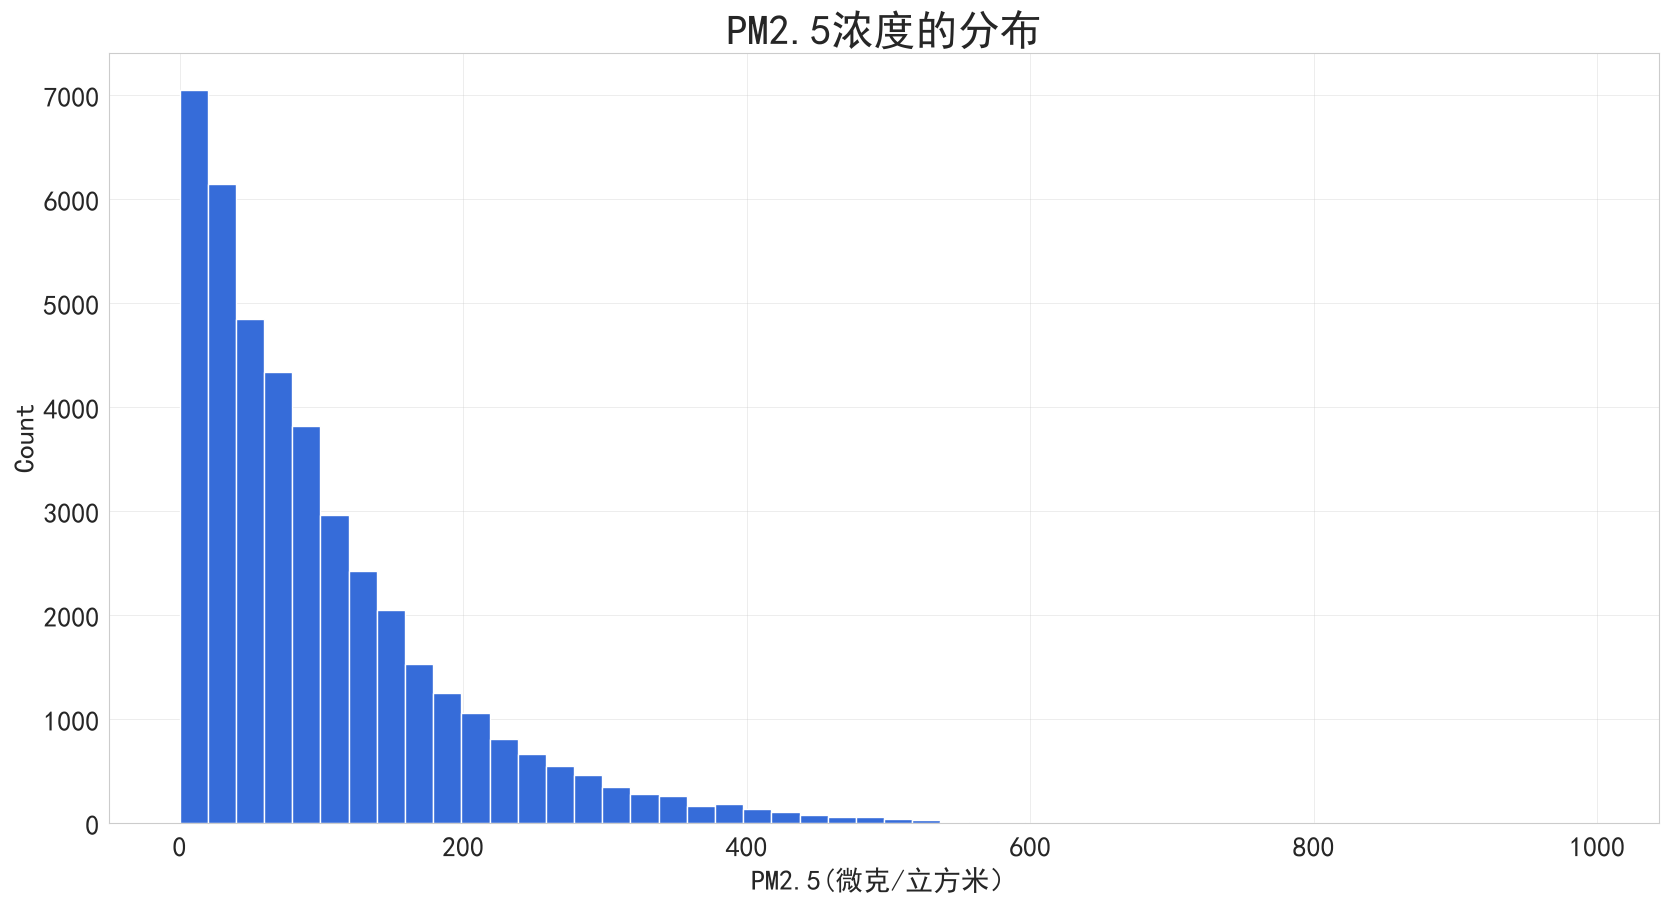

In [5]:
plt.figure(figsize=(20,10))
plt.hist(df['pm2.5'], bins=50)
plt.title('PM2.5浓度的分布',fontsize=30)
plt.xlabel('PM2.5(微克/立方米）',fontsize=20)
plt.ylabel('Count',fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.show()

pm2.5 的分布明显右偏：大部分时间浓度不高，但有一小段时间的PM2.5浓度非常高，这些极端高值把平均值往上拉了。所以描述「平时一般是多少」时，中位数比均值更有代表性。


## 4. 时间变化规律

这一节分别从年、月、小时三个尺度聚合，看 PM2.5 的长期变化、季节规律和一天之内的起伏。下面三张图依次是逐年变化、逐月均值和一天 24 小时的均值。这些规律一般和污染源排放以及气象上的扩散条件有关。


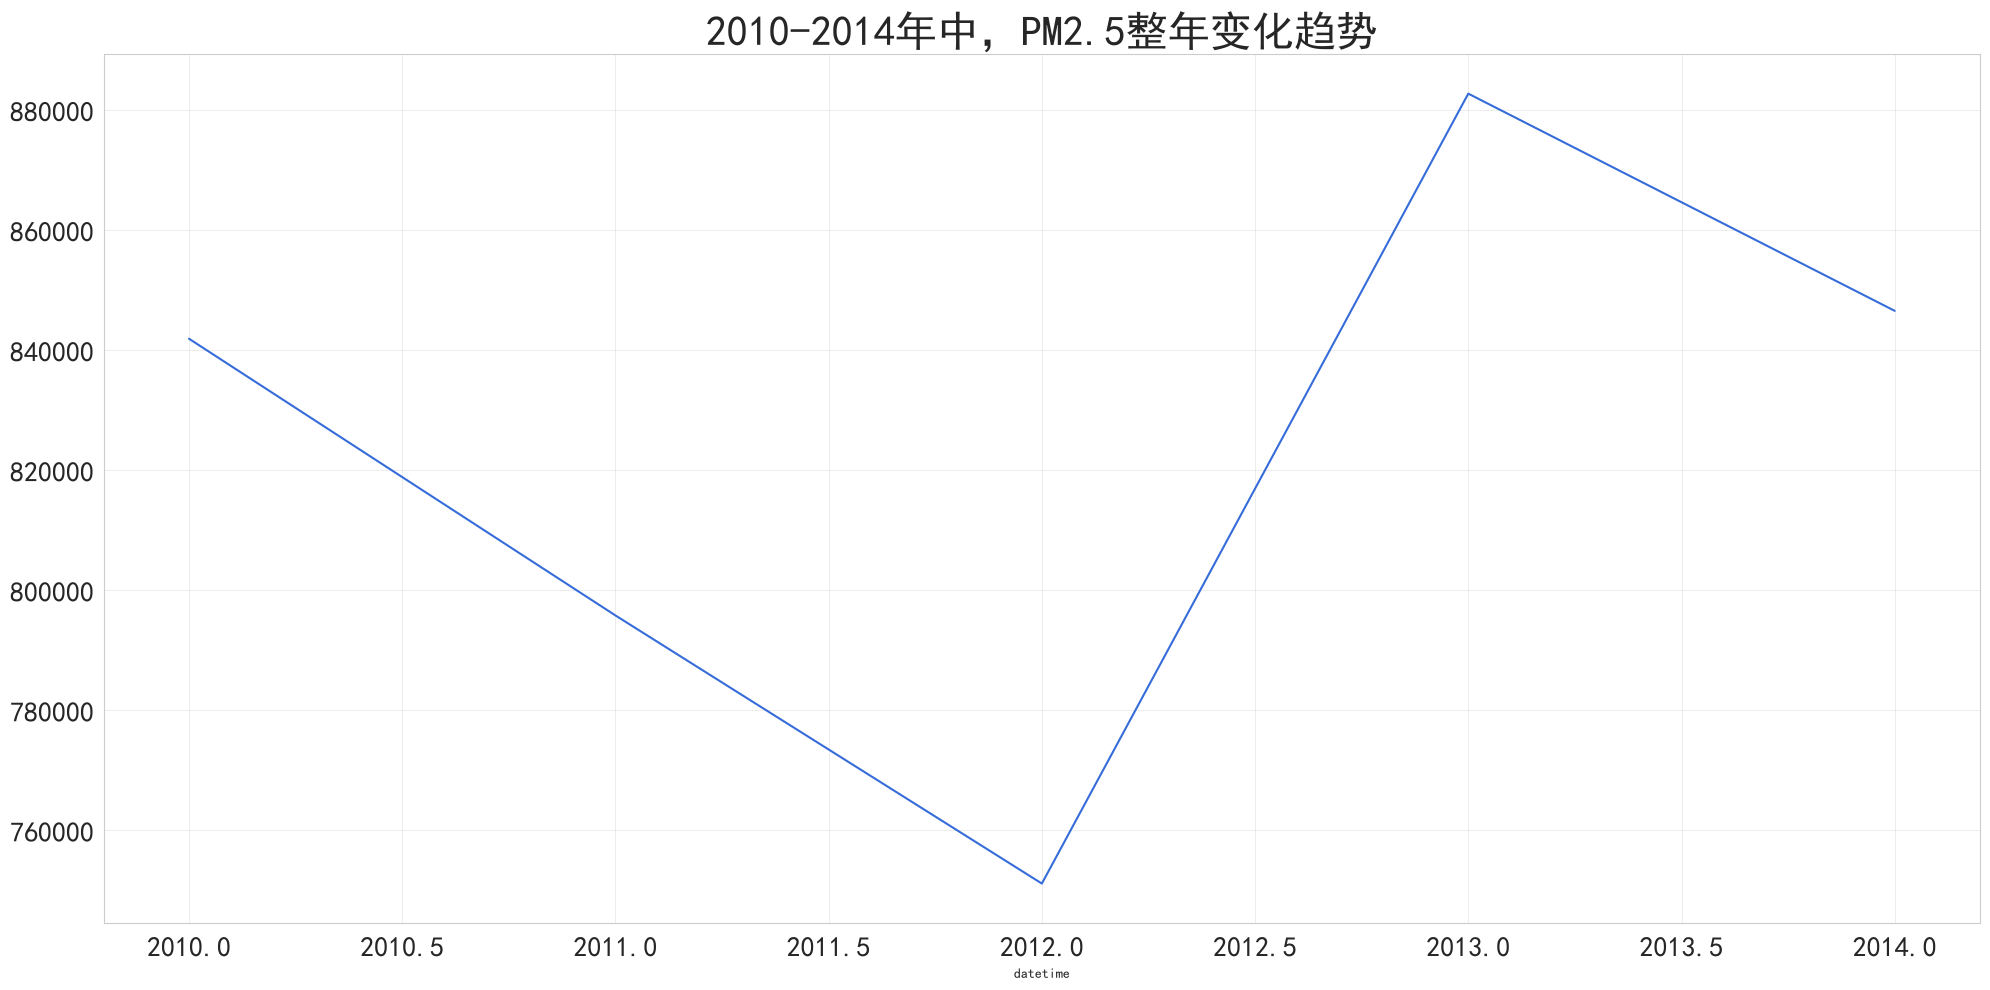

In [6]:
by_year = df.groupby(df.index.year)['pm2.5'].sum()
plt.figure(figsize=(20,10))
by_year.plot()
plt.title("2010-2014年中，PM2.5整年变化趋势",fontsize=30)
plt.xticks(rotation=0,fontsize=20)
plt.yticks(fontsize=20)
plt.tight_layout()
plt.show()

<bound method NDFrame.head of datetime
1     115.059061
2     125.736140
3      97.757593
4      83.709251
5      80.113051
6      96.513656
7      94.332328
8      79.996704
9      85.209421
10    120.401509
11    105.762639
12     98.200226
Name: pm2.5, dtype: float64>


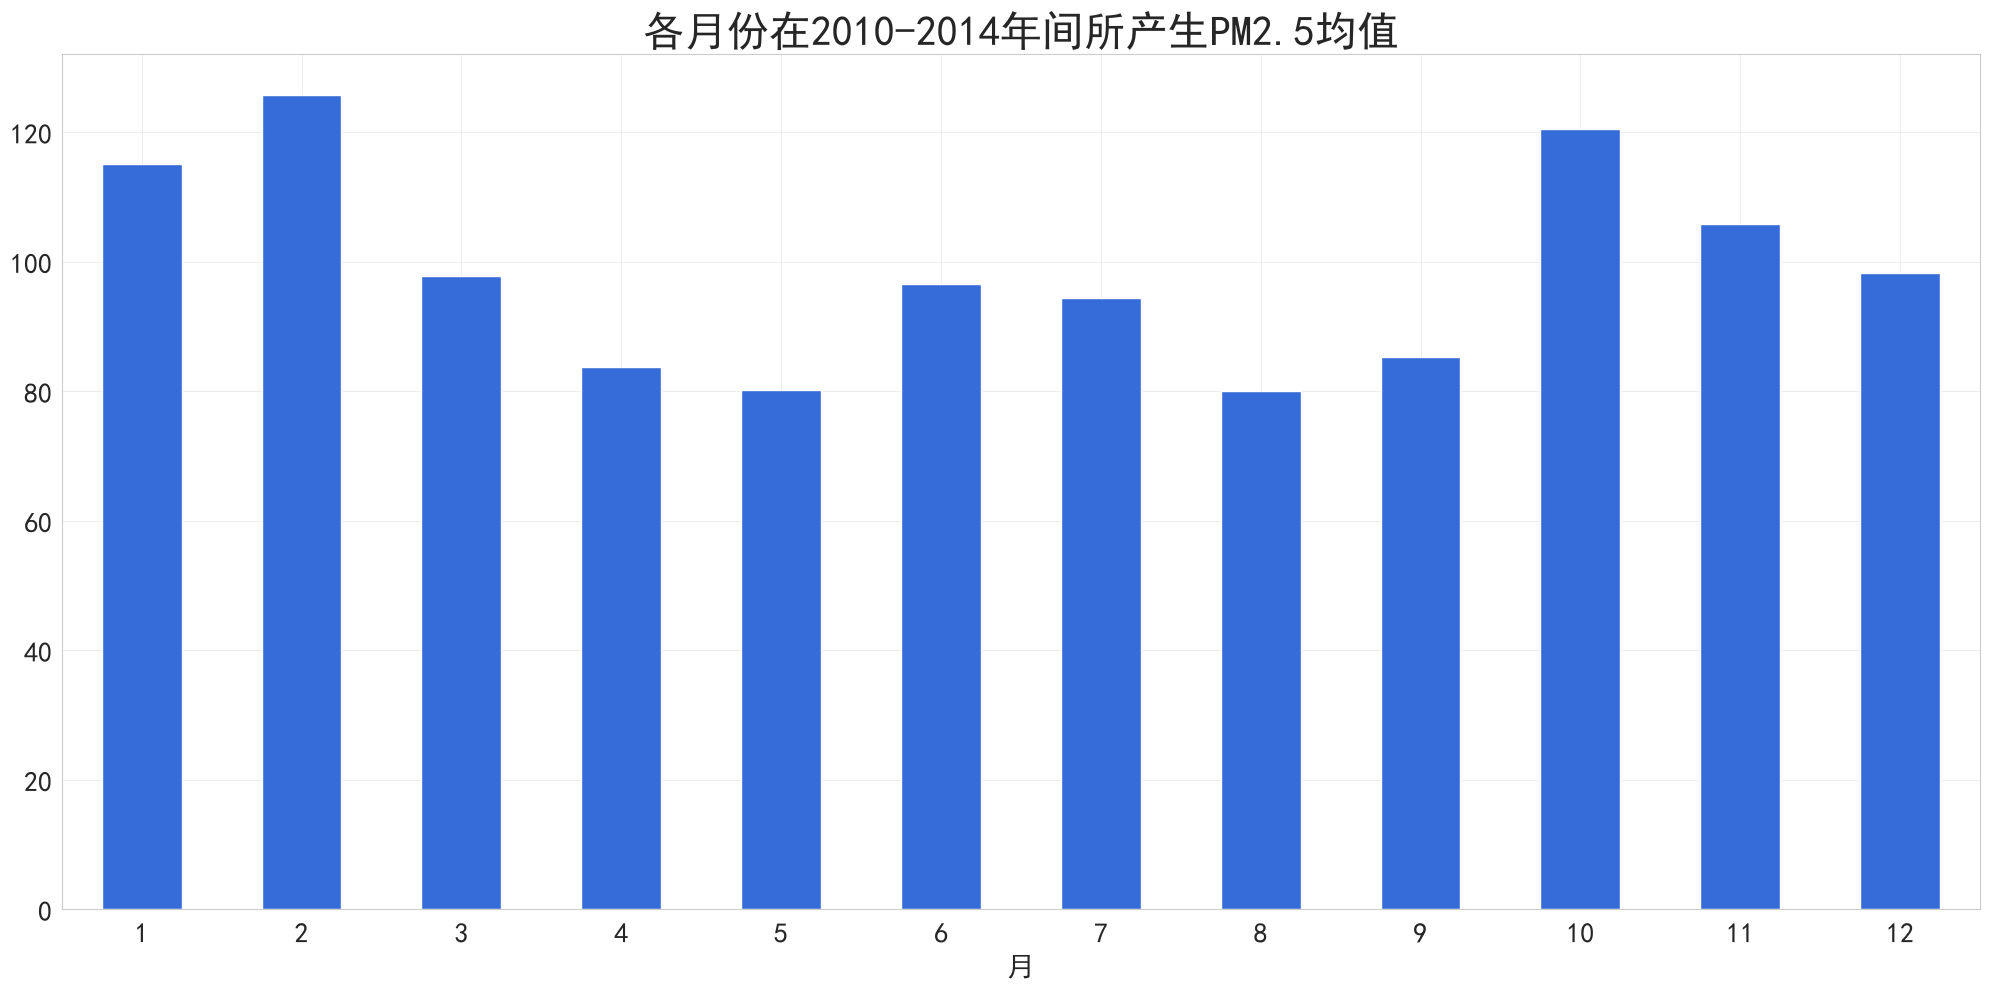

In [7]:
by_month = df.groupby(df.index.month)['pm2.5'].mean()
print(by_month.head)
plt.figure(figsize=(20,10))
by_month.plot(kind='bar')
plt.title("各月份在2010-2014年间所产生PM2.5均值",fontsize=30)
plt.xticks(rotation=0,fontsize=20)
plt.xlabel('月',fontsize=20)
plt.yticks(fontsize=20)
plt.tight_layout()
plt.show()

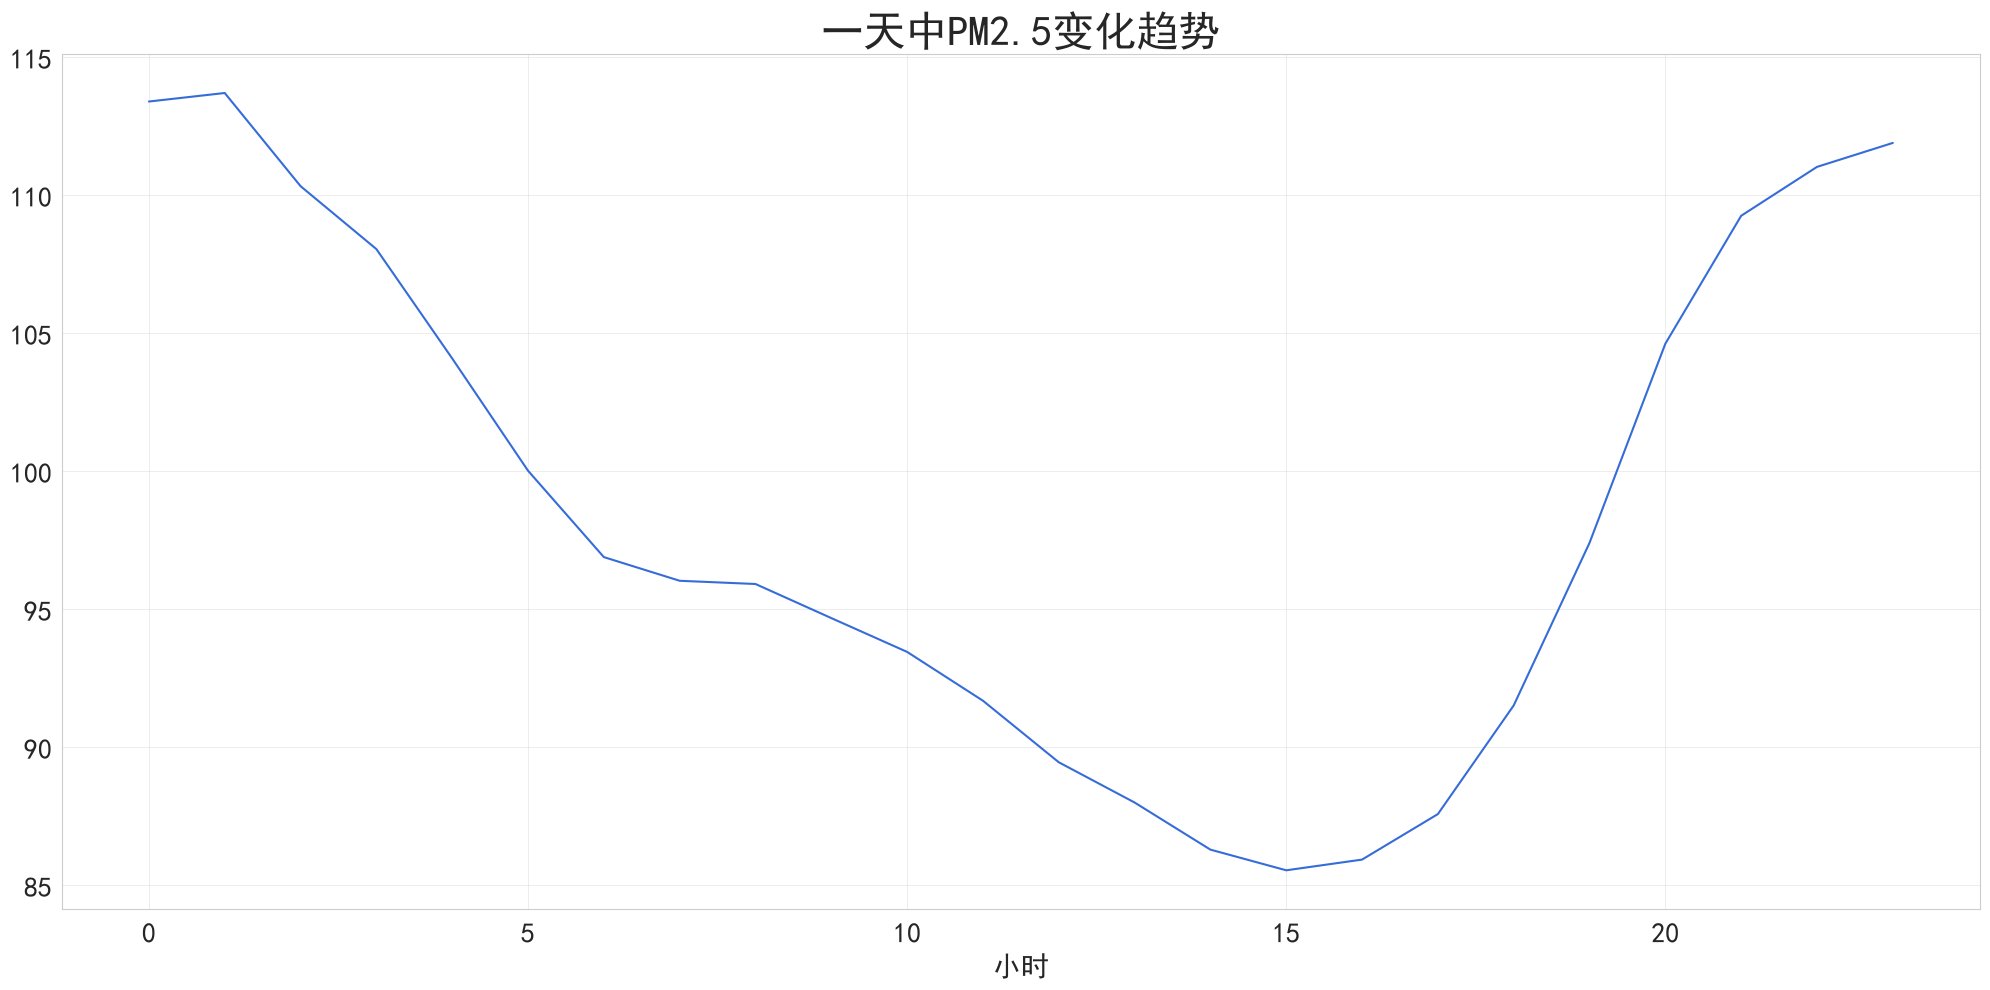

In [8]:
by_hours = df.groupby(df.index.hour)['pm2.5'].mean()
plt.figure(figsize=(20,10))
by_hours.plot()
plt.title('一天中PM2.5变化趋势',fontsize=30)
plt.xticks(rotation=0,fontsize=20)
plt.xlabel('小时',fontsize=20)
plt.yticks(fontsize=20)
plt.tight_layout()
plt.show()


**本节发现：**

1. 从逐年变化看，2010—2014 年 PM2.5 总体呈上升趋势。
2. 季节差异很明显：逐月均值在 2 月最高（约 125.7 微克/立方米）、8 月最低（约 80.0 微克/立方米），秋末到初春污染偏重，夏季最轻。
3. 一天之内也有规律：夜间到凌晨浓度较高（凌晨 1 点前后最高），午后到下午最低（15 点前后最低），白天后浓度会明显下降。


## 5. PM2.5 与气象因素的关系

这一节看 pm2.5 和气象因素之间的关系：先用散点图直观观察它和累积风速 Iws 的关系，再按风向分组、比较不同风向下的平均浓度。


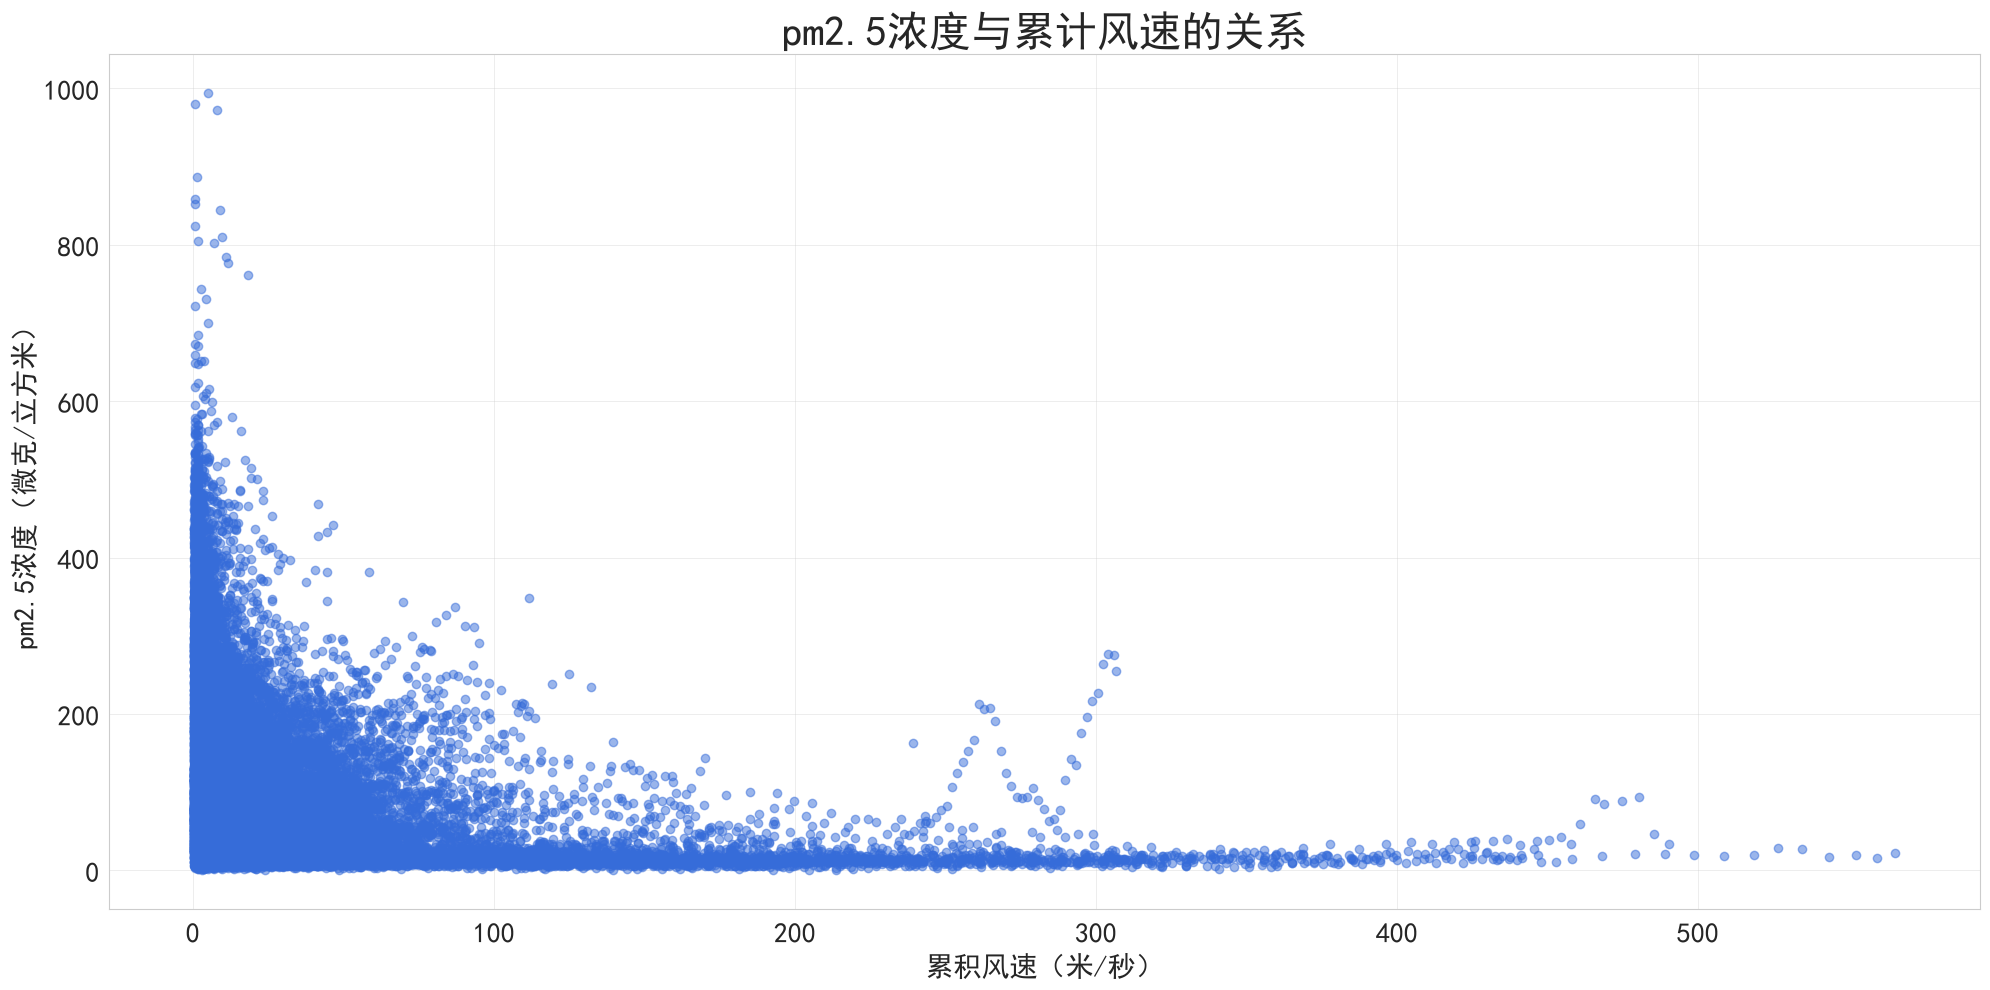

In [9]:
plt.figure(figsize=(20,10))
plt.scatter(df['Iws'], df['pm2.5'],alpha=0.5,label='累积风速（米/秒）')
plt.title('pm2.5浓度与累计风速的关系',fontsize=30)
plt.xlabel('累积风速（米/秒）',fontsize=20)
plt.xticks(fontsize=20)
plt.ylabel('pm2.5浓度（微克/立方米）',fontsize=20)
plt.yticks(fontsize=20)
plt.tight_layout()

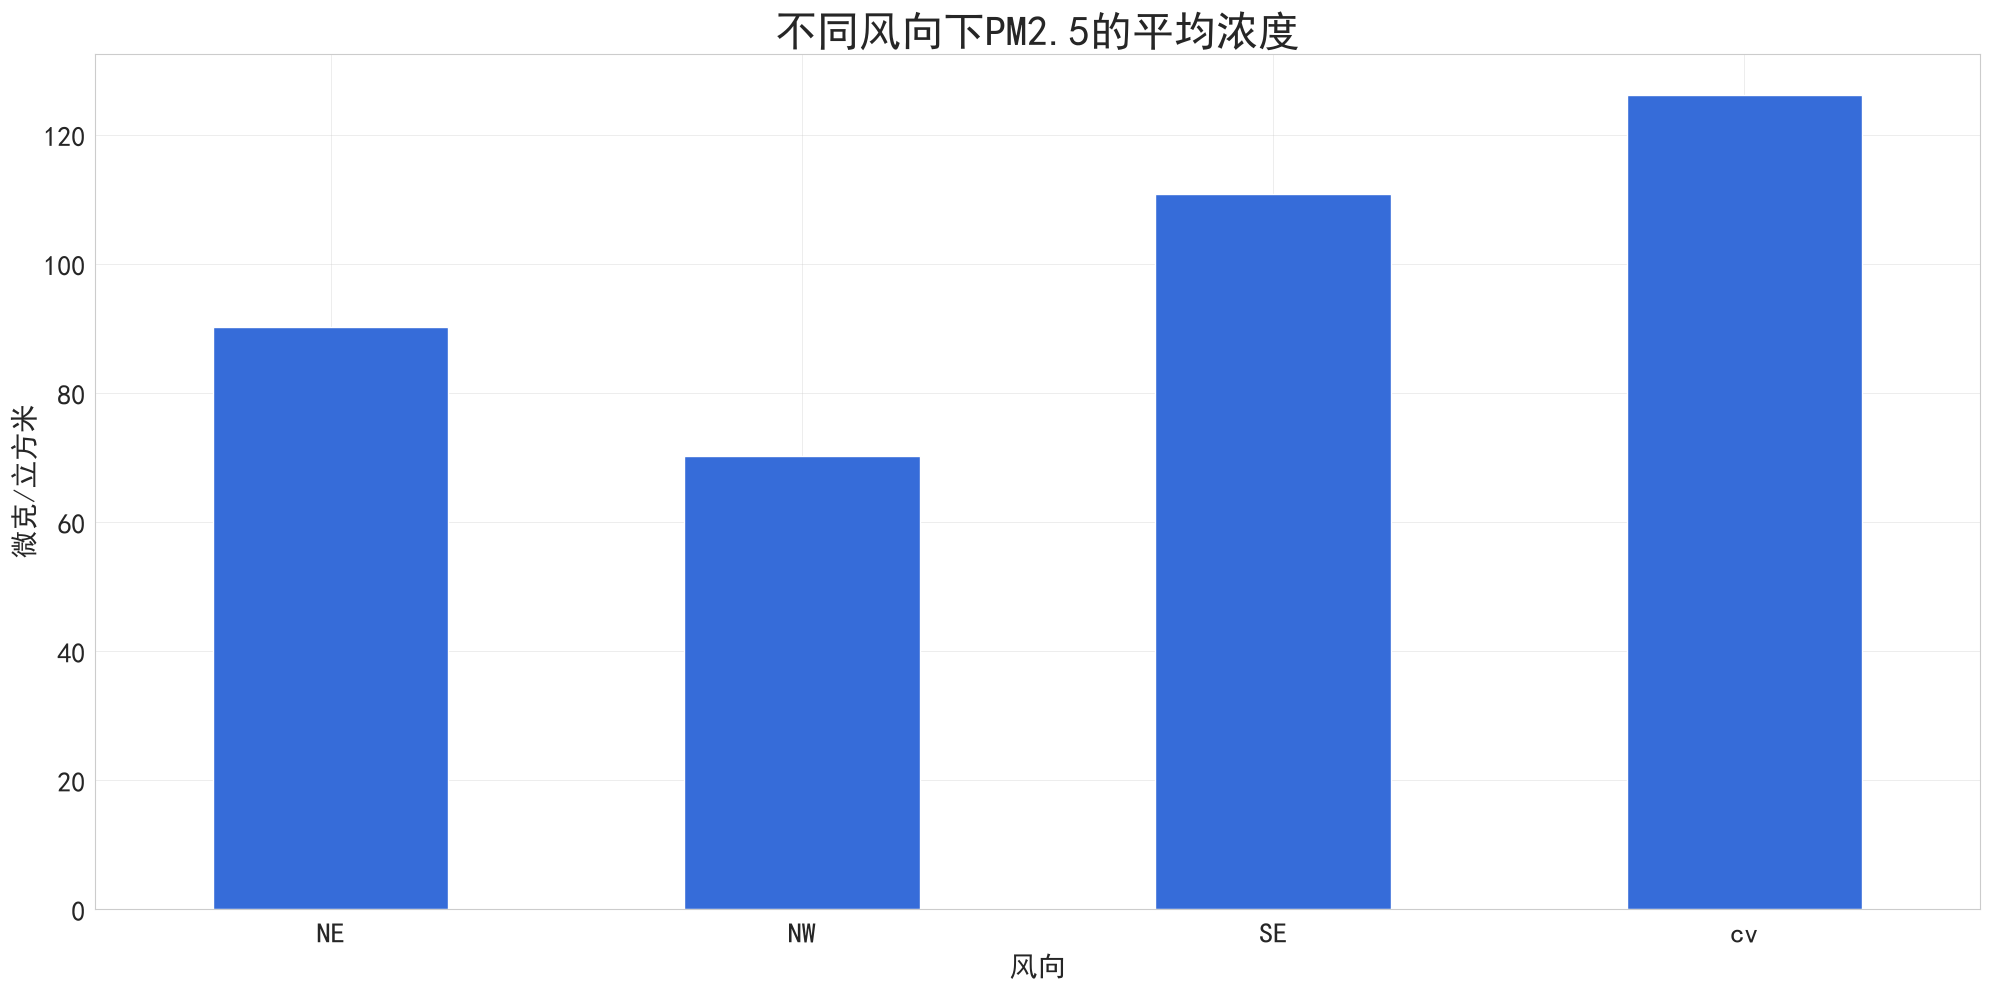

In [10]:
plt.figure(figsize=(20,10))
by_cbwd = df.groupby(df['cbwd'])['pm2.5'].mean()
by_cbwd.plot(kind='bar')
plt.title('不同风向下PM2.5的平均浓度',fontsize=30)
plt.xticks(rotation=0,fontsize=20)
plt.xlabel('风向',fontsize=20)
plt.ylabel('微克/立方米',fontsize=20)
plt.yticks(fontsize=20)
plt.tight_layout()



**本节发现：**

1. 散点图显示，累积风速越大，PM2.5 浓度整体越低，两者呈负相关。
2. 按风向分组比较，cv（静风/多变）、SE、NE、NW 下的 PM2.5 平均浓度依次降低，其中西北风 NW 时平均浓度最低。


## 6. 重度污染天与非重度污染天的对比
先把数据按天聚合（数值取当天均值、风向取当天出现最多的值），再把日均 PM2.5 大于 150 微克/立方米的天标记为重污染天（参照官方给出的PM2.5 重度污染的阈值），然后对比重污染天和普通天在气温、气压、风速、风向上有什么不同。


                 pm2.5       TEMP         PRES       DEWP         Iws cbwd
datetime                                                                  
2010-01-02  145.958333  -5.125000  1024.750000  -8.500000   24.860000   SE
2010-01-03   78.833333  -8.541667  1022.791667 -10.125000   70.937917   SE
2010-01-04   31.333333 -11.500000  1029.291667 -20.875000  111.160833   NW
2010-01-05   42.458333 -14.458333  1033.625000 -24.583333   56.920000   NW
2010-01-06   56.416667 -12.541667  1033.750000 -23.708333   18.511667   NE
            TEMP         PRES        Iws      DEWP
重度污染天                                             
否      15.458333  1015.625000  12.328333  2.291667
是       7.958333  1018.020833   6.285208  0.500000
cbwd    NE    NW    SE    cv
重度污染天                       
否      6.1  43.1  42.1   8.8
是      2.0  22.5  50.3  25.3


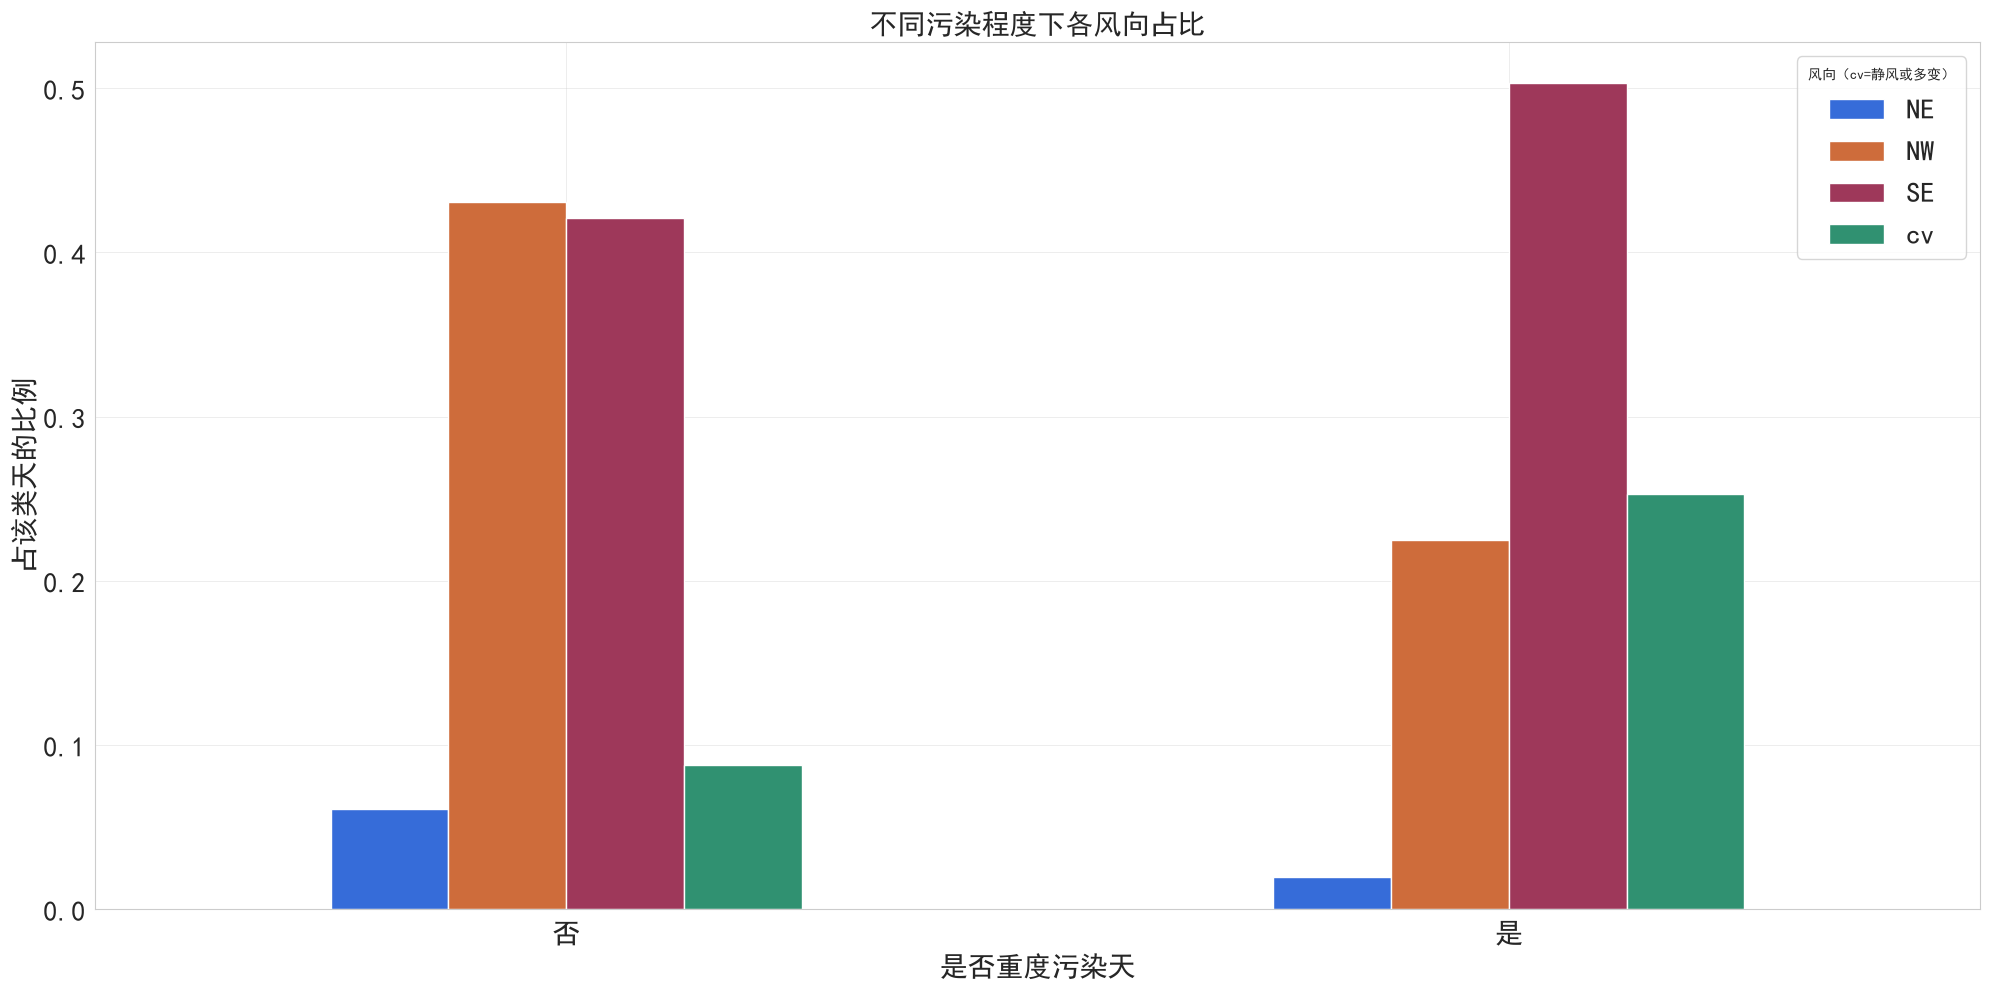

In [11]:
def _mode(s):
    m = s.mode()
    return m.iloc[0] if len(m) else np.nan
day = df.resample('D').agg({
    'pm2.5': 'mean', 'TEMP': 'mean', 'PRES': 'mean',
    'DEWP': 'mean', 'Iws': 'mean', 'cbwd': _mode
                          })
print(day.head())
day['重度污染天'] = pd.cut(day['pm2.5'],
                            bins=[-np.inf, 150, np.inf],
                            labels=['否', '是'])
print(day.groupby('重度污染天')[['TEMP','PRES','Iws','DEWP']].median())
wind = pd.crosstab(day['重度污染天'], day['cbwd'], normalize='index')
print((wind * 100).round(1))
wind.plot(kind='bar', figsize=(20, 10))
plt.title('不同污染程度下各风向占比',fontsize=20)
plt.xticks(rotation=0,fontsize=20)
plt.ylabel('占该类天的比例',fontsize=20)
plt.xlabel('是否重度污染天',fontsize=20)
plt.xticks(rotation=0,fontsize=20)
plt.yticks(fontsize=20)
plt.legend(title='风向（cv=静风或多变）',fontsize=20)
plt.tight_layout()
plt.show()


## 7. 结论

1. PM2.5 有明显的季节规律：逐月均值在 2 月最高（约 125.7 微克/立方米）、8 月最低（约 80.0 微克/立方米），秋冬季整体高于春夏季（见「各月份 PM2.5 均值」图）。
2. 在其他条件一定时，PM2.5 浓度和累积风速 Iws 呈负相关，风越大浓度越低；从风向角度看看，静风/多变（cv）时平均浓度最高，西北风（NW）时最低（见「PM2.5 与累积风速的关系」「不同风向下 PM2.5 的平均浓度」两张图）。
3. 按日均 PM2.5 大于 150 划分，重污染天大约有 356 天、占有效天数的 20% 左右；这些天里静风/多变（cv）的占比从普通天的约 9% 升到约 25%，西北风（NW）则从约 43% 降到约 23%，说明重污染天往往伴随着静风、缺少有利于扩散的西北风（见「不同污染程度下各风向占比」图）。

**不足与下一步：**

- 这次只做了描述性分析，得到的都是相关关系，不能据此说某个气象因素「导致」了污染。
- 逐年图用的是浓度总量、2010 年初还有一段缺失，年际趋势比较粗略。
- 下一步打算在进一步学习机器学习后找一找进一步优化的方向。


## 8. 复现说明

- 原始数据放在 `data/` 目录下，数据文件较大、没有上传，下载地址见 README；
- 需要的第三方库写在 `requirements.txt` 里，安装后从上到下依次运行本 Notebook 即可复现，分析中用到的图片都保存在 `figures/`。
